# Phase 1 — Compréhension des données : analyse univariée

**Projet Intégré — Analyse et prédiction du churn client** · ESPRIT School of Business · L3 Business Computing BI
**VIGIE · Groupe BI 5** — Raed Meddeb · Salsabil Ben Elhadj · Salah Chebbi · Ines Ayed
Tuteurs : Aymen Ben Brik et Hela Hammami

---

### Ce que contient ce notebook

| Étape | Question traitée |
|---|---|
| 1 | Le fichier chargé est-il bien celui fourni ? (intégrité, empreinte) |
| 2 | Quel est le **grain** des données et quelles sont les clés ? |
| 3 | Comment définit-on le **churn**, et quel est son taux selon le grain ? |
| 4 | Où sont les **valeurs manquantes**, et pourquoi ? |
| 5 | Comment se distribue chaque variable ? (**analyse univariée**) |
| 6 | Combien d'**outliers** par variable numérique ? (IQR et z-score) |
| 7 | **Tableau de synthèse** par variable : type, % manquants, outliers, décision |

### Règle de confidentialité appliquée ici
Ce notebook n'affiche **aucune ligne client ni aucun identifiant** : uniquement des comptages,
des distributions et des indicateurs agrégés. Les données restent dans `data/` (ignoré par git).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

RACINE = Path.cwd().resolve().parents[1]      # .../01_etl/notebooks -> racine du dépôt
sys.path.insert(0, str(RACINE))
from vigie import config, donnees, style

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 100, "display.width", 200)
style.appliquer()
C = config.COULEURS
fr = style.milliers

## 1. Chargement et intégrité

Le CSV est lu **tel quel** (tout en texte) : on ne laisse pas pandas deviner les types, pour ne perdre
aucune information (zéros en tête, dates au format `YYYYMMDD`, vides).
L'empreinte SHA-256 identifie précisément le fichier sur lequel tous nos chiffres sont calculés.

In [2]:
brut = donnees.charger_brut()
refs = donnees.charger_referentiels()
empreinte = donnees.empreinte()

attendu = {"Lignes": 483_536, "Colonnes": 32, "Clients distincts": 363_024, "Comptes distincts": 410_309}
observe = {
    "Lignes": len(brut),
    "Colonnes": brut.shape[1],
    "Clients distincts": brut["CUSTOMER_NO"].nunique(),
    "Comptes distincts": brut["ACCOUNT_NO"].nunique(),
}
controle = pd.DataFrame({"Attendu (doc. tuteurs)": attendu, "Observé": observe})
controle["Conforme"] = np.where(controle.iloc[:, 0] == controle.iloc[:, 1], "✔", "✘")
display(controle)
print("SHA-256 du fichier :", empreinte["sha256"])
print("Taille             :", fr(empreinte["octets"]), "octets")

,Attendu (doc. tuteurs),Observé,Conforme
Lignes,483536,483536,✔
Colonnes,32,32,✔
Clients distincts,363024,363024,✔
Comptes distincts,410309,410309,✔


SHA-256 du fichier : 858551b4293ee1abce4d3aaeac3dea07d817cfd80e111dd52dcff5b06d9fb732
Taille             : 75 095 492 octets


Les quatre volumes annoncés dans le document de description des données sont retrouvés à l'unité près.

### Fichiers de référence
Chaque code du fichier principal doit exister dans son référentiel (intégrité référentielle).

In [3]:
liens = {
    "ACCOUNT_CATEGORY": ("ACCOUNT_CATEGORY", "CATEGORY_ID"),
    "CLOSURE_REASON": ("CLOSURE_REASON", "REASON_ID"),
    "CURRENCY": ("CURRENCY", "CURRENCY_CODE"),
    "INDUSTRY": ("INDUSTRY", "INDUSTRY_CODE"),
    "LOB": ("TARGET", "TARGET_CODE"),
}
lignes = []
for colonne, (fichier, cle) in liens.items():
    codes_source = set(brut[colonne].dropna().unique())
    codes_ref = set(refs[fichier][cle])
    lignes.append({
        "Colonne": colonne, "Référentiel": f"{fichier}.xlsx", "Clé": cle,
        "Modalités du référentiel": len(codes_ref),
        "Codes utilisés": len(codes_source),
        "Codes orphelins": len(codes_source - codes_ref),
        "Codes jamais utilisés": len(codes_ref - codes_source),
    })
display(pd.DataFrame(lignes).set_index("Colonne"))

,Référentiel,Clé,Modalités du référentiel,Codes utilisés,Codes orphelins,Codes jamais utilisés
Colonne,,,,,,
ACCOUNT_CATEGORY,ACCOUNT_CATEGORY.xlsx,CATEGORY_ID,14,14,0,0
CLOSURE_REASON,CLOSURE_REASON.xlsx,REASON_ID,12,12,0,0
CURRENCY,CURRENCY.xlsx,CURRENCY_CODE,5,5,0,0
INDUSTRY,INDUSTRY.xlsx,INDUSTRY_CODE,22,21,0,1
LOB,TARGET.xlsx,TARGET_CODE,6,6,0,0


**Lecture.** Aucun code orphelin : les cinq jointures sont sûres. Un seul code de référentiel n'est jamais
utilisé (une section d'activité), ce qui est sans conséquence.

## 2. Grain et clés

Une ligne du fichier est un **rapprochement client / compte / produit**. Avant tout calcul, il faut
savoir ce que l'on compte.

In [4]:
df = donnees.typer(brut)
avec_compte = df[df["ACCOUNT_NO"].notna()]

lignes_par_compte = avec_compte.groupby("ACCOUNT_NO").size()
lignes_par_client = df.groupby("CUSTOMER_NO").size()
comptes_par_client = avec_compte.groupby("CUSTOMER_NO")["ACCOUNT_NO"].nunique()

grain = pd.Series({
    "Lignes du fichier": len(df),
    "Lignes strictement identiques (doublons exacts)": int(df.duplicated().sum()),
    "Lignes sans compte (clients sans compte renseigné)": int(df["ACCOUNT_NO"].isna().sum()),
    "Part des lignes sans compte": f"{df['ACCOUNT_NO'].isna().mean():.1%}",
    "Comptes distincts": lignes_par_compte.size,
    "Comptes présents sur plusieurs lignes": int((lignes_par_compte > 1).sum()),
    "Clients distincts": lignes_par_client.size,
    "Clients avec au moins un compte": comptes_par_client.size,
    "Clients sans compte": lignes_par_client.size - comptes_par_client.size,
    "Nombre maximal de lignes pour un client (plafond)": int(lignes_par_client.max()),
    "Un compte appartient-il à un seul client ?": "Oui" if avec_compte.groupby("ACCOUNT_NO")["CUSTOMER_NO"].nunique().max() == 1 else "Non",
}, name="Valeur")
display(grain.to_frame())

,Valeur
Lignes du fichier,483536
Lignes strictement identiques (doublons exacts),8335
Lignes sans compte (clients sans compte renseigné),43984
Part des lignes sans compte,9.1%
Comptes distincts,410309
Comptes présents sur plusieurs lignes,14365
Clients distincts,363024
Clients avec au moins un compte,319040
Clients sans compte,43984
Nombre maximal de lignes pour un client (plafond),100


In [5]:
# Qu'est-ce qui varie entre deux lignes d'un même compte ?
multi = avec_compte[avec_compte["ACCOUNT_NO"].isin(lignes_par_compte[lignes_par_compte > 1].index)]
variation = multi.groupby("ACCOUNT_NO").nunique(dropna=True).gt(1).sum()
variation = variation[variation > 0].sort_values(ascending=False)
display(variation.rename("Comptes où la colonne prend plusieurs valeurs").to_frame())

,Comptes où la colonne prend plusieurs valeurs
ACCT_CLOSE_DATE,11807
CLOSURE_REASON,805
FIXEDRATE,16


**Constats sur le grain**

* Un compte appartient toujours à **un seul client** : `CUSTOMER_NO → ACCOUNT_NO` est une relation 1-N propre.
* Quand un compte apparaît sur plusieurs lignes, seules la **date de clôture** et, plus rarement, le **motif**
  ou le **taux** changent. Les autres attributs du compte sont constants.
* Environ 9 % des lignes décrivent un client **sans compte** : elles alimentent la dimension client, pas les faits.

**Décision — grain d'analyse.** Nous travaillons à deux grains, selon la question :

| Grain | Construction | Usage |
|---|---|---|
| **Compte** | une ligne par `ACCOUNT_NO` ; si plusieurs dates de clôture, on garde la **première** | entrepôt (table de faits), KPI, série temporelle |
| **Client** | une ligne par `CUSTOMER_NO` | segmentation, modèle de churn |

La première date de clôture est retenue car c'est elle qui marque l'événement de churn ; les dates
suivantes sont des régularisations du même compte.

In [6]:
comptes = donnees.grain_compte(df)
clients = donnees.grain_client(df, comptes)
date_ref = donnees.date_reference(df)
print(f"Grain compte : {fr(len(comptes))} lignes   |   Grain client : {fr(len(clients))} lignes")
print(f"Date de référence (dernier événement de compte observé) : {date_ref:%d/%m/%Y}")

Grain compte : 410 309 lignes   |   Grain client : 363 024 lignes
Date de référence (dernier événement de compte observé) : 19/02/2024


## 3. Définition du churn et taux selon le grain

Conformément au document de description : **churn = 1 si `ACCOUNT_STATUS = "Closed"`**, 0 si `"Active"`,
ligne exclue si le statut est vide.

In [7]:
statuts_par_client = comptes.groupby("CUSTOMER_NO")["CHURN"].agg(["min", "max"])
clients_mixtes = int((statuts_par_client["min"] != statuts_par_client["max"]).sum())

taux = pd.DataFrame({
    "Effectif": [int(avec_compte["ACCOUNT_STATUS"].notna().sum()), len(comptes),
                 int(clients["CHURN"].notna().sum()), len(clients)],
    "Churn": [int((avec_compte["ACCOUNT_STATUS"] == "Closed").sum()), int(comptes["CHURN"].sum()),
              int(clients["CHURN"].sum()), int(clients["CHURN"].sum())],
}, index=["Ligne (statut renseigné)", "Compte", "Client ayant au moins un compte", "Client (tous, y c. sans compte)"])
taux["Taux de churn"] = (taux["Churn"] / taux["Effectif"]).map("{:.1%}".format)
display(taux)
print("Clients ayant à la fois un compte actif et un compte clos :", clients_mixtes)

,Effectif,Churn,Taux de churn
Ligne (statut renseigné),439552,177270,40.3%
Compte,410309,148215,36.1%
Client ayant au moins un compte,319040,117345,36.8%
"Client (tous, y c. sans compte)",363024,117345,32.3%


Clients ayant à la fois un compte actif et un compte clos : 0


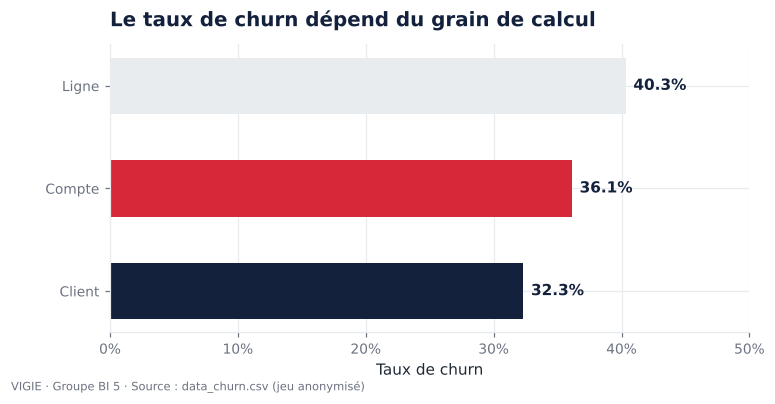

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
valeurs = (taux["Churn"] / taux["Effectif"]).iloc[[0, 1, 3]]
barres = ax.barh(["Ligne", "Compte", "Client"], valeurs, color=[C["brume"], C["churn"], C["encre"]], height=0.55)
for b, v in zip(barres, valeurs):
    ax.text(v + 0.006, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", fontweight="bold", color=C["encre"])
ax.set_xlim(0, 0.5)
ax.xaxis.set_major_formatter(style.pourcent)
ax.invert_yaxis()
ax.set_title("Le taux de churn dépend du grain de calcul")
ax.set_xlabel("Taux de churn")
style.enregistrer(fig, "01_taux_churn_par_grain")
plt.show()

**Lecture.** On retrouve les ordres de grandeur annoncés : ≈ 40 % des lignes, ≈ 36 % des comptes, ≈ 32 % des clients.
Un taux « par ligne » surestime le churn, car les comptes clos sont plus souvent répétés.

**Fait marquant : aucun client n'a à la fois un compte actif et un compte clos.** Un client est soit entièrement
actif, soit entièrement parti. La définition fine « churn client = clôture de *tous* ses comptes » coïncide donc
exactement avec « au moins un compte clos ». C'est ce qui nous permet de modéliser le churn **au grain client**
sans ambiguïté (phase 4).

Le déséquilibre est **modéré** (≈ 36 % de positifs) : aucune technique de rééquilibrage n'est nécessaire a priori.

## 4. Valeurs manquantes

On compte les manquants au grain **ligne** (pour se comparer au document des tuteurs) puis au grain **naturel**
de chaque variable (client ou compte), qui est celui qui a un sens métier.

In [9]:
manquants = pd.DataFrame({
    "Grain naturel": ["Client" if c in donnees.COLONNES_CLIENT else "Compte" for c in df.columns],
    "Manquants (lignes)": df.isna().sum(),
    "% manquants (lignes)": (df.isna().mean() * 100).round(1),
})
pct_naturel = {}
for c in df.columns:
    base = clients if c in donnees.COLONNES_CLIENT else comptes
    pct_naturel[c] = round(base[c].isna().mean() * 100, 1)
manquants["% manquants (grain naturel)"] = pd.Series(pct_naturel)
manquants = manquants.sort_values("% manquants (lignes)", ascending=False)
display(manquants)

,Grain naturel,Manquants (lignes),% manquants (lignes),% manquants (grain naturel)
MATURITYDATE,Compte,442994,91.6,92.5
FIXEDRATE,Compte,432878,89.5,90.1
PRODUCT_STATUS,Compte,425498,88.0,89.6
STARTDATE,Compte,425494,88.0,89.6
SALARY,Client,343229,71.0,69.1
CLOSURE_REASON,Compte,342070,70.7,67.2
ACCT_CLOSE_DATE,Compte,306266,63.3,63.9
COMPLETED_FILE,Client,235933,48.8,55.0
AMOUNT,Compte,210844,43.6,37.7
PRODUCT_GROUP,Compte,202223,41.8,36.9


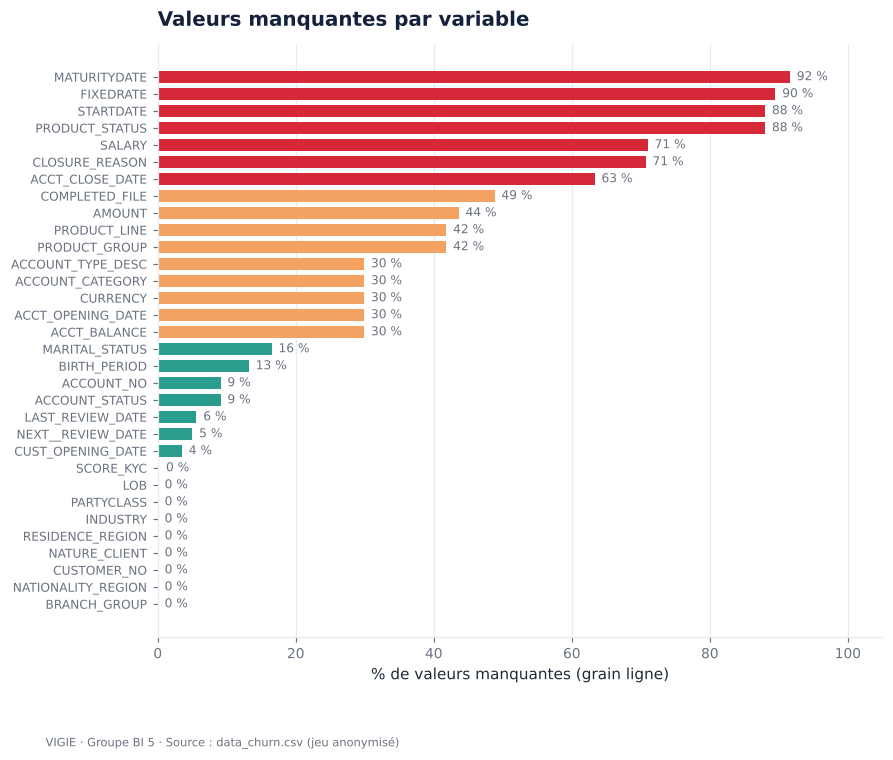

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 7))
m = manquants["% manquants (lignes)"].sort_values()
couleurs = [C["churn"] if v >= 60 else C["ambre"] if v >= 20 else C["retention"] for v in m]
ax.barh(m.index, m, color=couleurs, height=0.7)
for i, v in enumerate(m):
    ax.text(v + 1, i, f"{v:.0f} %", va="center", fontsize=8, color=C["gris"])
ax.set_xlim(0, 105)
ax.set_xlabel("% de valeurs manquantes (grain ligne)")
ax.set_title("Valeurs manquantes par variable")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8)
style.enregistrer(fig, "01_valeurs_manquantes")
plt.show()

### Les vides ne sont pas tous de même nature

Pour chaque variable de compte, on compare le taux de vide entre comptes **actifs** et comptes **clos**.

In [11]:
variables_compte = ["ACCT_OPENING_DATE", "ACCOUNT_CATEGORY", "CURRENCY", "ACCT_BALANCE", "ACCT_CLOSE_DATE",
                    "CLOSURE_REASON", "PRODUCT_GROUP", "PRODUCT_LINE", "AMOUNT", "STARTDATE", "MATURITYDATE",
                    "FIXEDRATE", "PRODUCT_STATUS"]
vides_statut = (comptes.groupby("ACCOUNT_STATUS")[variables_compte]
                .agg(lambda s: round(s.isna().mean() * 100, 1)).T)
vides_statut.columns = [f"% vide — {c}" for c in vides_statut.columns]
vides_statut["Écart (points)"] = (vides_statut.iloc[:, 1] - vides_statut.iloc[:, 0]).round(1)
display(vides_statut.sort_values("Écart (points)", ascending=False))

,% vide — Active,% vide — Closed,Écart (points)
ACCT_OPENING_DATE,0.0,67.8,67.8
ACCOUNT_CATEGORY,0.0,67.8,67.8
CURRENCY,0.0,67.8,67.8
ACCT_BALANCE,0.0,67.8,67.8
AMOUNT,15.0,77.7,62.7
PRODUCT_LINE,14.7,76.0,61.3
PRODUCT_GROUP,14.7,76.0,61.3
FIXEDRATE,89.1,91.9,2.8
MATURITYDATE,92.0,93.4,1.4
PRODUCT_STATUS,89.1,90.4,1.3


**Typologie des vides** (utilisée dans le tableau de synthèse final) :

| Type de vide | Variables | Explication |
|---|---|---|
| **Structurel** | toutes les colonnes de compte et de produit sur les lignes sans `ACCOUNT_NO` | le client n'a pas de compte : il n'y a rien à renseigner |
| **Métier** | `ACCT_CLOSE_DATE`, `CLOSURE_REASON` | un compte actif n'a ni date ni motif de clôture |
| **Métier** | `STARTDATE`, `MATURITYDATE`, `FIXEDRATE`, `PRODUCT_STATUS` | ne concernent que les produits à échéance (crédits, placements) |
| **Lié à la clôture** ⚠ | `ACCT_OPENING_DATE`, `ACCOUNT_CATEGORY`, `CURRENCY`, `ACCT_BALANCE`, `PRODUCT_GROUP`, `AMOUNT` | vides pour ≈ 68 % des comptes clos, **jamais** pour les actifs |
| **Déclaratif / anonymisation** | `SALARY`, `MARITAL_STATUS`, `BIRTH_PERIOD`, `COMPLETED_FILE` | non déclaré, ou masqué pour garantir le k-anonymat |

⚠ **Point d'attention majeur pour la phase 4.** Les vides « liés à la clôture » ne sont pas un défaut de qualité
ordinaire : ils **révèlent la cible**. Savoir que le solde est vide suffit presque à savoir que le compte est clos.
Ces colonnes — et tout indicateur dérivé de leur vide — sont donc exclues des variables explicatives
(contrôle détaillé dans `04_machine_learning/notebooks/03_churn_ml.ipynb`).

## 5. Analyse univariée

### 5.1 Variables qualitatives du client (grain client)

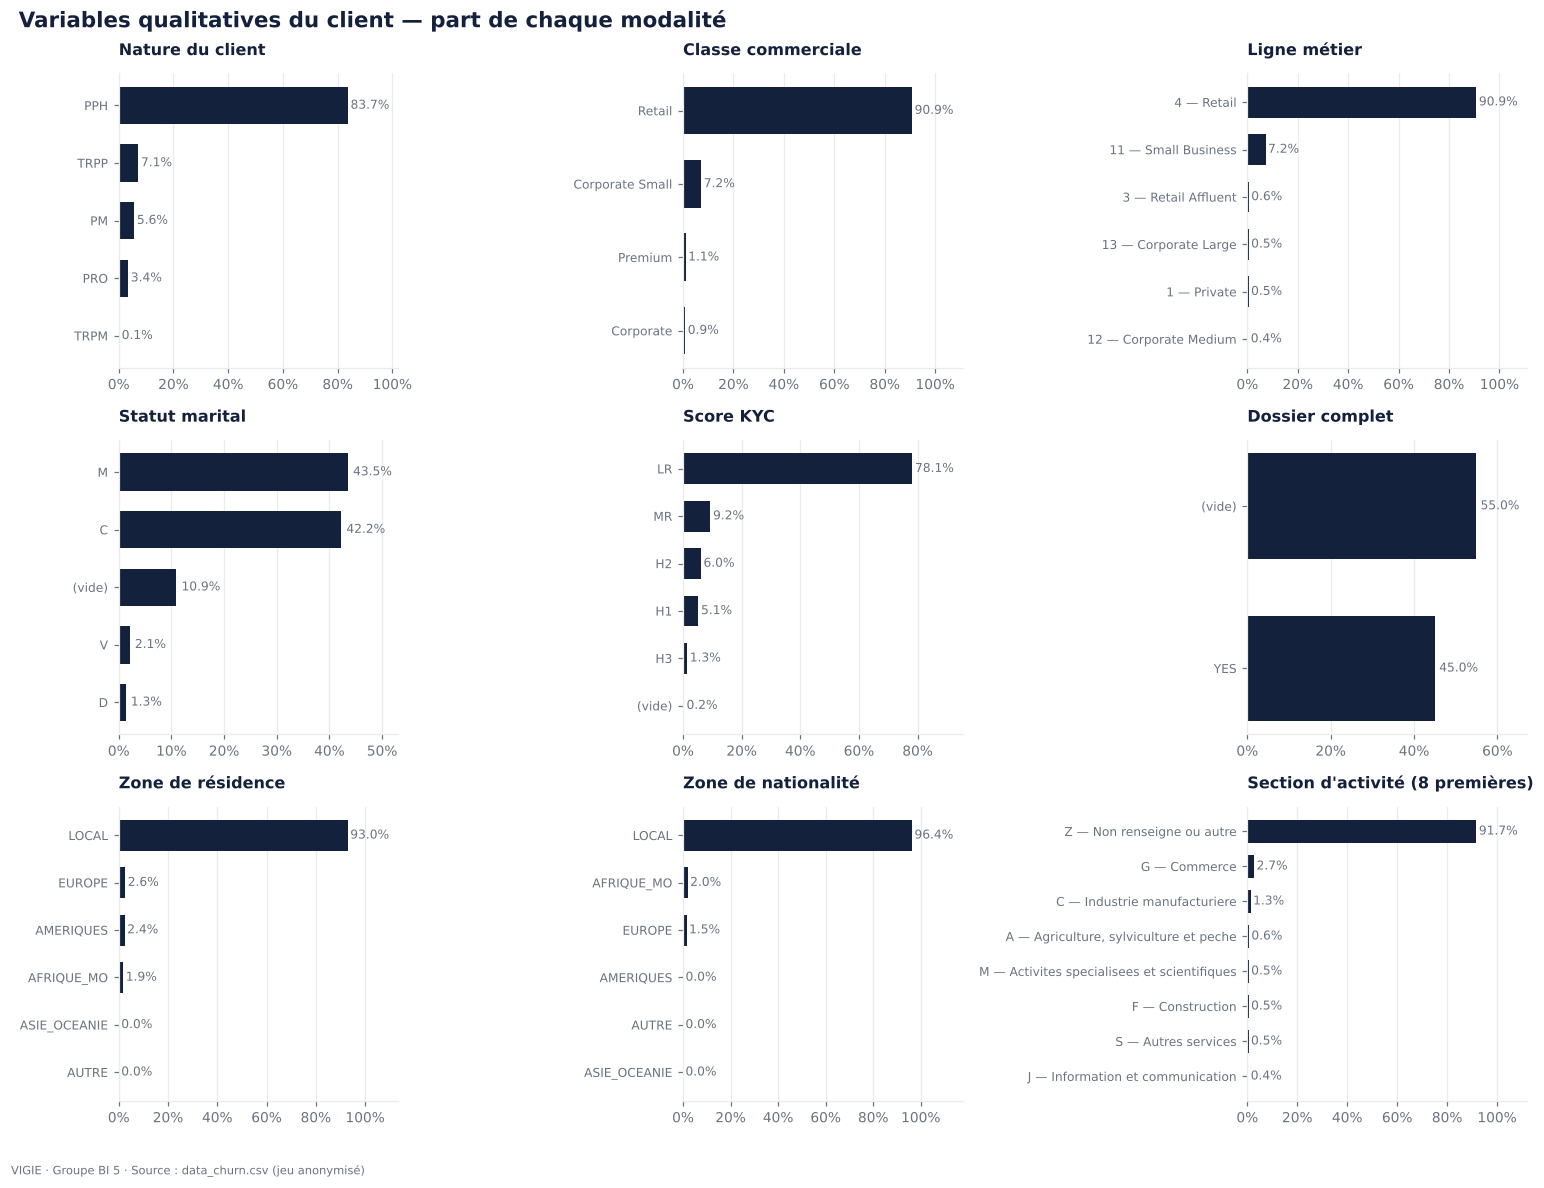

In [12]:
def tableau_modalites(serie: pd.Series, libelles: dict | None = None, top: int = 8) -> pd.DataFrame:
    """Effectif et part de chaque modalité (les vides forment une modalité)."""
    s = serie.astype("object").where(serie.notna(), "(vide)")
    t = s.value_counts().to_frame("Effectif")
    t["Part"] = (t["Effectif"] / t["Effectif"].sum()).map("{:.1%}".format)
    if libelles:
        t.insert(0, "Libellé", [libelles.get(i, "") for i in t.index])
    return t.head(top)


def barres_modalites(ax, serie, titre, couleur, top=8, libelles=None):
    s = serie.astype("object").where(serie.notna(), "(vide)")
    parts = (s.value_counts(normalize=True)).head(top)[::-1]
    noms = [f"{i} — {libelles[i]}" if libelles and i in libelles else str(i) for i in parts.index]
    ax.barh(noms, parts, color=couleur, height=0.65)
    for i, v in enumerate(parts):
        ax.text(v + 0.01, i, f"{v:.1%}", va="center", fontsize=8, color=C["gris"])
    ax.set_xlim(0, max(parts.max() * 1.22, 0.1))
    ax.xaxis.set_major_formatter(style.pourcent)
    ax.set_title(titre, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)


lib_secteur = dict(zip(refs["INDUSTRY"]["INDUSTRY_CODE"], refs["INDUSTRY"]["DESCRIPTION"]))
lib_lob = dict(zip(refs["TARGET"]["TARGET_CODE"], refs["TARGET"]["DESCRIPTION"]))

fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
plan = [
    ("NATURE_CLIENT", "Nature du client", None), ("PARTYCLASS", "Classe commerciale", None),
    ("LOB", "Ligne métier", lib_lob), ("MARITAL_STATUS", "Statut marital", None),
    ("SCORE_KYC", "Score KYC", None), ("COMPLETED_FILE", "Dossier complet", None),
    ("RESIDENCE_REGION", "Zone de résidence", None), ("NATIONALITY_REGION", "Zone de nationalité", None),
    ("INDUSTRY", "Section d'activité (8 premières)", lib_secteur),
]
for ax, (col, titre, lib) in zip(axes.ravel(), plan):
    barres_modalites(ax, clients[col], titre, C["encre"], libelles=lib)
fig.suptitle("Variables qualitatives du client — part de chaque modalité", x=0.01, ha="left",
             fontweight="bold", color=C["encre"], fontsize=14)
fig.tight_layout()
style.enregistrer(fig, "01_univarie_client_qualitatif")
plt.show()

In [13]:
for col, titre, lib in plan:
    display(Markdown(f"**{titre}** (`{col}`) — {clients[col].nunique()} modalités"))
    display(tableau_modalites(clients[col], lib))

**Nature du client** (`NATURE_CLIENT`) — 5 modalités

,Effectif,Part
NATURE_CLIENT,,
PPH,303908,83.7%
TRPP,25888,7.1%
PM,20474,5.6%
PRO,12460,3.4%
TRPM,294,0.1%


**Classe commerciale** (`PARTYCLASS`) — 4 modalités

,Effectif,Part
PARTYCLASS,,
Retail,329842,90.9%
Corporate Small,26211,7.2%
Premium,3812,1.1%
Corporate,3159,0.9%


**Ligne métier** (`LOB`) — 6 modalités

,Libellé,Effectif,Part
LOB,,,
4,Retail,329842,90.9%
11,Small Business,26211,7.2%
3,Retail Affluent,2008,0.6%
13,Corporate Large,1865,0.5%
1,Private,1804,0.5%
12,Corporate Medium,1294,0.4%


... (8 outputs left out)

**Zone de nationalité** (`NATIONALITY_REGION`) — 6 modalités

,Effectif,Part
NATIONALITY_REGION,,
LOCAL,349793,96.4%
AFRIQUE_MO,7238,2.0%
EUROPE,5581,1.5%
AMERIQUES,169,0.0%
AUTRE,136,0.0%
ASIE_OCEANIE,107,0.0%


**Section d'activité (8 premières)** (`INDUSTRY`) — 21 modalités

,Libellé,Effectif,Part
INDUSTRY,,,
Z,Non renseigne ou autre,332986,91.7%
G,Commerce,9798,2.7%
C,Industrie manufacturiere,4830,1.3%
A,"Agriculture, sylviculture et peche",2253,0.6%
M,Activites specialisees et scientifiques,1986,0.5%
F,Construction,1878,0.5%
S,Autres services,1739,0.5%
J,Information et communication,1297,0.4%


**Lecture — variables qualitatives du client**

* La clientèle est très majoritairement **de particuliers** : 84 % de personnes physiques (`PPH`) et 91 % de
  clients du segment **Retail**. Les entreprises (`PM`) et professionnels (`PRO`) forment une minorité à suivre à part.
* Les catégories `TRPP` et `TRPM` (7 % des clients) n'ont quasiment **jamais de compte** : elles sortent
  d'elles-mêmes du périmètre du churn.
* `PARTYCLASS` et `LOB` portent presque la même information (le segment commercial) : une seule des deux
  suffira en modélisation.
* `INDUSTRY` vaut `Z` (« non renseigné ou autre ») pour plus de 9 clients sur 10 : la variable est surtout
  informative pour les personnes morales et les professionnels.
* `COMPLETED_FILE` ne prend que la valeur `YES` : le vide signifie « dossier incomplet ». On la recode en 0/1.
* Zones de résidence et de nationalité : 93 % et 96 % de `LOCAL`. Les autres modalités sont rares.

### 5.2 Groupes d'agences

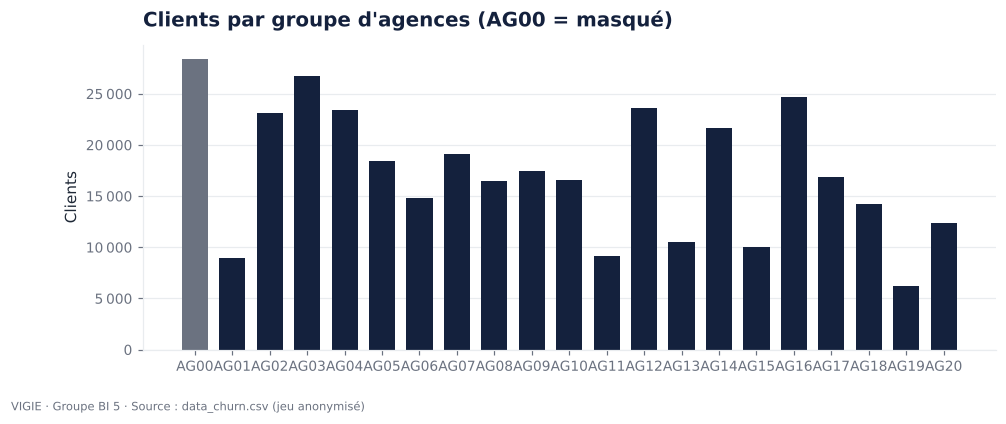

Groupe le plus petit : 6 228 clients · le plus grand : 28 378 · AG00 (masqué) : 7.8% des clients


In [14]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ag = clients["BRANCH_GROUP"].value_counts().sort_index()
ax.bar(ag.index, ag.values, color=[C["gris"] if i == "AG00" else C["encre"] for i in ag.index], width=0.7)
ax.yaxis.set_major_formatter(style.milliers)
ax.set_title("Clients par groupe d'agences (AG00 = masqué)")
ax.set_ylabel("Clients")
ax.grid(axis="x", visible=False)
style.enregistrer(fig, "01_univarie_agences")
plt.show()
print(f"Groupe le plus petit : {fr(ag.min())} clients · le plus grand : {fr(ag.max())} · AG00 (masqué) : {ag['AG00'] / ag.sum():.1%} des clients")

Les 21 regroupements ont tous une taille significative (de 6 000 à 28 000 clients) : ils peuvent servir d'axe d'analyse.
`AG00` regroupe les agences masquées par l'anonymisation et ne s'interprète pas.

### 5.3 Variables quantitatives du client

In [15]:
clients["AGE"] = date_ref.year - (clients["BIRTH_PERIOD"] + 2)
clients["ANCIENNETE_CLIENT"] = (date_ref - clients["CUST_OPENING_DATE"]).dt.days / 365.25
clients["MOIS_DEPUIS_REVUE"] = (date_ref - clients["LAST_REVIEW_DATE"]).dt.days / 30.4375
clients["MOIS_AVANT_PROCHAINE_REVUE"] = (clients["NEXT__REVIEW_DATE"] - date_ref).dt.days / 30.4375

quanti_client = {
    "AGE": "Âge (années, milieu de tranche)",
    "ANCIENNETE_CLIENT": "Ancienneté client (années)",
    "NB_COMPTES": "Nombre de comptes",
    "SALARY": "Revenu déclaré",
    "MOIS_DEPUIS_REVUE": "Mois depuis la dernière revue",
    "MOIS_AVANT_PROCHAINE_REVUE": "Mois avant la prochaine revue",
}


def resume(serie: pd.Series) -> pd.Series:
    s = serie.dropna().astype(float)
    return pd.Series({
        "n": len(s), "Moyenne": s.mean(), "Écart-type": s.std(), "Min": s.min(), "Q1": s.quantile(.25),
        "Médiane": s.median(), "Q3": s.quantile(.75), "Max": s.max(),
        "Asymétrie": s.skew(), "Mode": s.mode().iloc[0],
    })


stats_client = pd.DataFrame({lib: resume(clients.loc[clients["NB_COMPTES"] > 0, col] if col == "NB_COMPTES" else clients[col])
                             for col, lib in quanti_client.items()}).T
display(stats_client.round(2))

,n,Moyenne,Écart-type,Min,Q1,Médiane,Q3,Max,Asymétrie,Mode
"Âge (années, milieu de tranche)",339679.0,48.09,16.74,2.00,37.00,47.00,62.00,87.00,0.17,42.00
Ancienneté client (années),347422.0,11.71,6.59,0.13,6.13,10.38,18.13,24.13,0.20,21.39
Nombre de comptes,319040.0,1.29,1.16,1.00,1.00,1.00,1.00,92.00,17.53,1.00
Revenu déclaré,112277.0,794.09,657.31,1.00,400.00,400.00,1000.00,5000.00,2.19,400.00
Mois depuis la dernière revue,336120.0,52.41,42.54,0.59,20.63,44.62,69.65,256.62,1.61,69.65
Mois avant la prochaine revue,338950.0,-8.27,43.33,-232.61,-21.65,-3.61,21.39,58.41,-1.67,-21.65


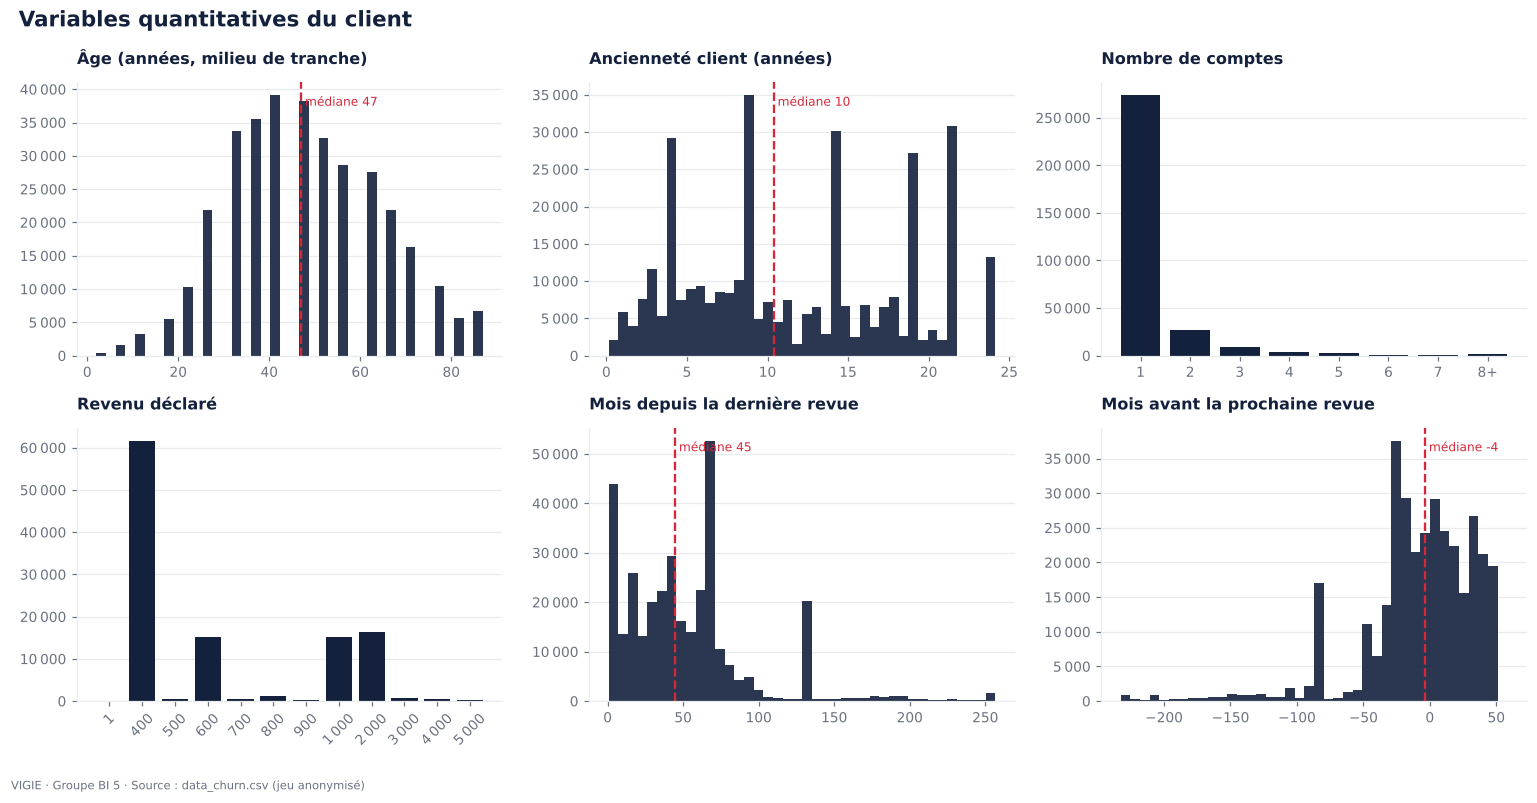

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, lib) in zip(axes.ravel(), quanti_client.items()):
    s = clients[col].dropna()
    if col == "NB_COMPTES":
        s = s[s > 0].clip(upper=8)
        v = s.value_counts().sort_index()
        ax.bar([str(int(i)) if i < 8 else "8+" for i in v.index], v.values, color=C["encre"])
    elif col == "SALARY":
        v = s.value_counts().sort_index()
        ax.bar([fr(i) for i in v.index], v.values, color=C["encre"])
        ax.tick_params(axis="x", rotation=45)
    else:
        ax.hist(s, bins=40, color=C["encre"], alpha=0.9)
        ax.axvline(s.median(), color=C["churn"], lw=1.5, ls="--")
        ax.text(s.median(), ax.get_ylim()[1] * 0.95, f" médiane {s.median():.0f}", color=C["churn"], fontsize=8, va="top")
    ax.yaxis.set_major_formatter(style.milliers)
    ax.set_title(lib, fontsize=10.5)
    ax.grid(axis="x", visible=False)
fig.suptitle("Variables quantitatives du client", x=0.01, ha="left", fontweight="bold", color=C["encre"], fontsize=14)
fig.tight_layout()
style.enregistrer(fig, "01_univarie_client_quantitatif")
plt.show()

**Lecture — variables quantitatives du client**

* **Âge** : distribution étalée, centrée vers 47 ans. L'âge est reconstruit au milieu de la tranche de naissance
  de 5 ans : c'est un ordre de grandeur, pas une valeur exacte. Les mineurs existent (comptes d'épargne ouverts
  par les parents).
* **Ancienneté** : des « marches » visibles, car `CUST_OPENING_DATE` est généralisée (trimestre, année ou
  période de 5 ans selon le client). À interpréter par tranches.
* **Nombre de comptes** : très concentré — la grande majorité des clients n'a **qu'un seul compte**.
* **Revenu déclaré** : arrondi à un chiffre significatif, donc une douzaine de valeurs seulement, et vide pour
  ≈ 7 clients sur 10. C'est en pratique une variable ordinale. La valeur `1` est une saisie technique.
* **Revues de dossier** : la dernière revue date en médiane de près de 4 ans ; une valeur négative de
  « mois avant la prochaine revue » signifie que la revue est **en retard**.

### 5.4 Variables du compte (grain compte)

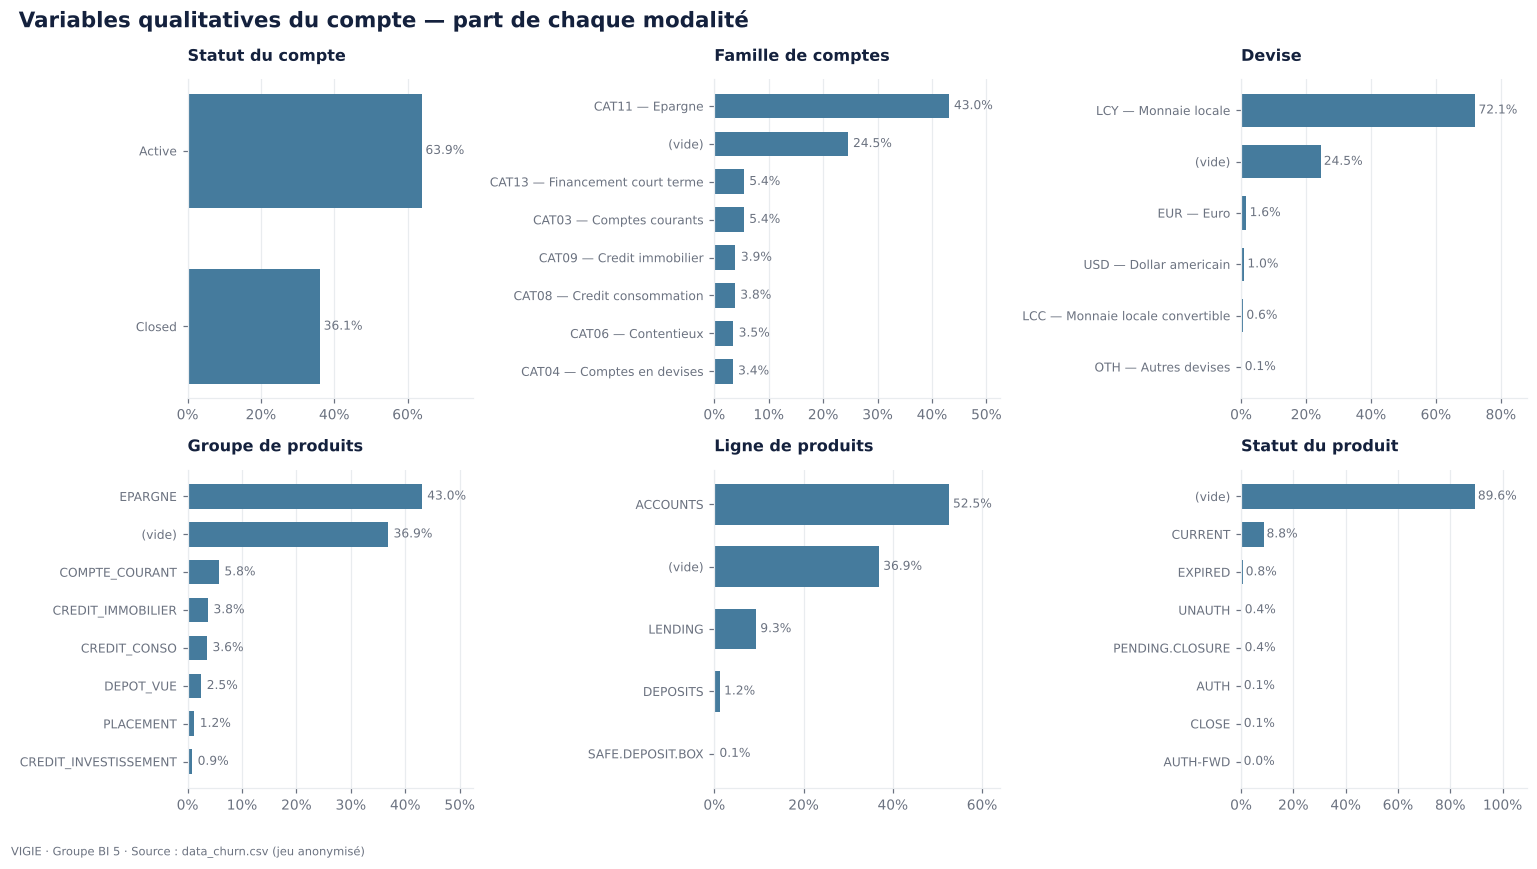

In [17]:
lib_cat = dict(zip(refs["ACCOUNT_CATEGORY"]["CATEGORY_ID"], refs["ACCOUNT_CATEGORY"]["DESCRIPTION"]))
lib_dev = dict(zip(refs["CURRENCY"]["CURRENCY_CODE"], refs["CURRENCY"]["DESCRIPTION"]))
lib_motif = dict(zip(refs["CLOSURE_REASON"]["REASON_ID"], refs["CLOSURE_REASON"]["DESCRIPTION"]))

fig, axes = plt.subplots(2, 3, figsize=(14, 7.6))
plan_compte = [
    ("ACCOUNT_STATUS", "Statut du compte", None), ("ACCOUNT_CATEGORY", "Famille de comptes", lib_cat),
    ("CURRENCY", "Devise", lib_dev), ("PRODUCT_GROUP", "Groupe de produits", None),
    ("PRODUCT_LINE", "Ligne de produits", None), ("PRODUCT_STATUS", "Statut du produit", None),
]
for ax, (col, titre, lib) in zip(axes.ravel(), plan_compte):
    barres_modalites(ax, comptes[col], titre, C["ciel"], libelles=lib)
fig.suptitle("Variables qualitatives du compte — part de chaque modalité", x=0.01, ha="left",
             fontweight="bold", color=C["encre"], fontsize=14)
fig.tight_layout()
style.enregistrer(fig, "01_univarie_compte_qualitatif")
plt.show()

In [18]:
clos = comptes[comptes["CHURN"] == 1]
motifs = tableau_modalites(clos["CLOSURE_REASON"], lib_motif, top=13)
display(Markdown("**Motifs de clôture** (comptes clos uniquement)"))
display(motifs)

**Motifs de clôture** (comptes clos uniquement)

,Libellé,Effectif,Part
CLOSURE_REASON,,,
RSN01,Autre,120129,81.1%
(vide),,13509,9.1%
RSN02,Cessation d'activite,10547,7.1%
RSN03,Changement d'adresse,1803,1.2%
RSN05,Deces,902,0.6%
RSN12,Transfert interne,418,0.3%
RSN10,Refus de credit,269,0.2%
RSN11,Tarification,248,0.2%
RSN04,Changement d'employeur,220,0.1%


**Lecture — variables du compte**

* L'**épargne** domine très largement le portefeuille ; viennent ensuite les financements court terme et les
  comptes courants. La devise est la **monnaie locale** dans l'écrasante majorité des cas.
* Le motif de clôture est `RSN01 — Autre` dans la grande majorité des cas : il est **peu informatif**. Les motifs
  « concurrentiels » (offre concurrente, tarification, qualité de service) sont marginaux. On ne peut donc pas
  expliquer le churn par le motif déclaré ; il faut passer par le profil du client.

### 5.5 Variables quantitatives du compte

In [19]:
quanti_compte = {"ACCT_BALANCE": "Solde du compte", "AMOUNT": "Montant du produit", "FIXEDRATE": "Taux fixe (%)"}
stats_compte = pd.DataFrame({lib: resume(comptes[col]) for col, lib in quanti_compte.items()}).T
display(stats_compte.round(2))

solde = comptes["ACCT_BALANCE"].dropna()
montant = comptes["AMOUNT"].dropna()
print(f"Soldes négatifs (comptes débiteurs) : {fr((solde < 0).sum())} soit {(solde < 0).mean():.1%} des soldes renseignés")
print(f"Soldes nuls                        : {fr((solde == 0).sum())} soit {(solde == 0).mean():.1%}")
print(f"Soldes au plafond haut ({fr(solde.max())})  : {fr((solde == solde.max()).sum())} comptes")
print(f"Soldes au plafond bas ({fr(solde.min())}) : {fr((solde == solde.min()).sum())} comptes")
print(f"Montants au plafond ({fr(montant.max())})    : {fr((montant == montant.max()).sum())} comptes")

,n,Moyenne,Écart-type,Min,Q1,Médiane,Q3,Max,Asymétrie,Mode
Solde du compte,309831.0,-2054.71,3.040538e+05,-11000000.0,0.0,6.0,1600.0,1.100000e+07,-4.60,0.0
Montant du produit,255796.0,12868754.50,1.953694e+08,-44000000.0,4.6,560.0,19000.0,9.000000e+09,34.01,0.0
Taux fixe (%),40442.0,9.10,2.480000e+00,0.0,8.5,10.0,11.0,1.350000e+01,-1.13,11.0


Soldes négatifs (comptes débiteurs) : 60 387 soit 19.5% des soldes renseignés
Soldes nuls                        : 62 994 soit 20.3%
Soldes au plafond haut (11 000 000)  : 40 comptes
Soldes au plafond bas (-11 000 000) : 42 comptes
Montants au plafond (9 000 000 000)    : 52 comptes


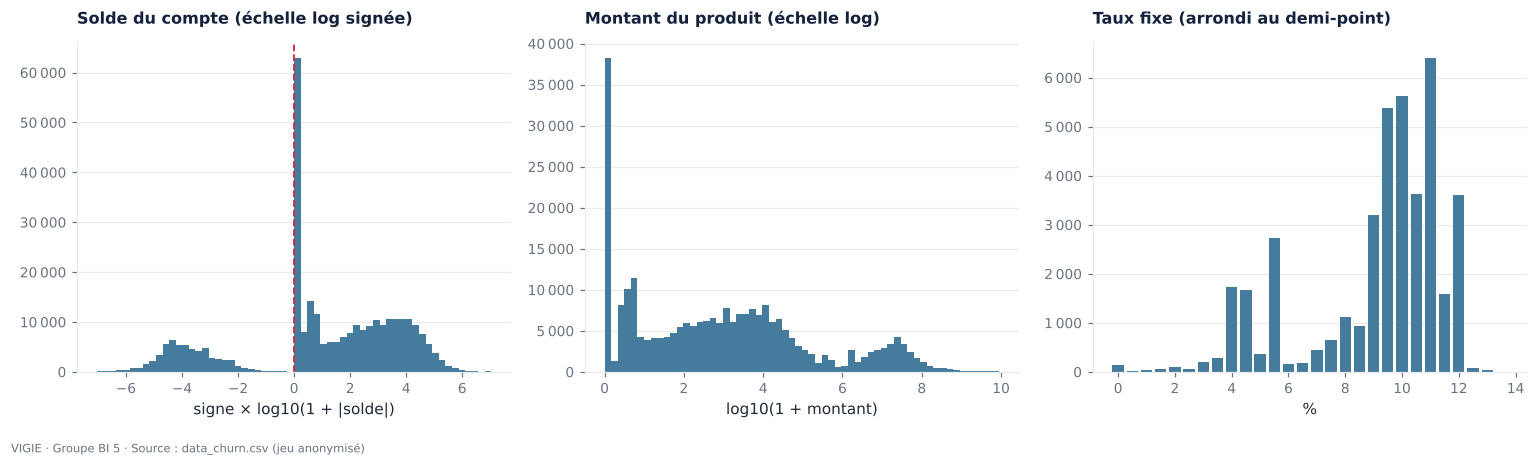

In [20]:
def log_signe(x):
    """Échelle logarithmique qui conserve le signe : utile pour des soldes négatifs et très étalés."""
    return np.sign(x) * np.log10(1 + np.abs(x))


fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(log_signe(solde), bins=60, color=C["ciel"])
axes[0].axvline(0, color=C["churn"], lw=1.2, ls="--")
axes[0].set_title("Solde du compte (échelle log signée)", fontsize=10.5)
axes[0].set_xlabel("signe × log10(1 + |solde|)")
axes[1].hist(np.log10(1 + montant.clip(lower=0)), bins=60, color=C["ciel"])
axes[1].set_title("Montant du produit (échelle log)", fontsize=10.5)
axes[1].set_xlabel("log10(1 + montant)")
taux_fixe = comptes["FIXEDRATE"].dropna().value_counts().sort_index()
axes[2].bar(taux_fixe.index, taux_fixe.values, width=0.4, color=C["ciel"])
axes[2].set_title("Taux fixe (arrondi au demi-point)", fontsize=10.5)
axes[2].set_xlabel("%")
for ax in axes:
    ax.yaxis.set_major_formatter(style.milliers)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.enregistrer(fig, "01_univarie_compte_quantitatif")
plt.show()

**Lecture — variables quantitatives du compte**

* **Solde** : distribution extrêmement étalée et asymétrique, avec une masse en zéro et une part notable de
  **soldes négatifs** (≈ 1 solde sur 5). Ces derniers ne sont pas des erreurs : ce sont des comptes **débiteurs**
  (découverts, encours de crédit). Les valeurs extrêmes sont **plafonnées** par l'anonymisation (± 11 000 000) :
  quelques dizaines de comptes atteignent exactement la borne, ce n'est pas un phénomène métier.
* **Montant** : même forme, encore plus étalée, avec la même accumulation artificielle sur la valeur plafond.
* **Taux fixe** : valeurs discrètes (demi-points), renseignées seulement pour les crédits et les placements.
  Les crédits (médiane de 9 à 11 % selon le type) sont un peu au-dessus des placements (médiane 8 %).

En conséquence, on raisonne sur ces montants en **ordre de grandeur** (médiane, tranches), jamais en total absolu.

### 5.6 Variables de date

In [21]:
dates = {
    "CUST_OPENING_DATE": ("Entrée en relation", clients), "LAST_REVIEW_DATE": ("Dernière revue", clients),
    "NEXT__REVIEW_DATE": ("Prochaine revue", clients), "ACCT_OPENING_DATE": ("Ouverture du compte", comptes),
    "ACCT_CLOSE_DATE": ("Clôture du compte", comptes), "STARTDATE": ("Début du produit", comptes),
    "MATURITYDATE": ("Échéance du produit", comptes),
}
resume_dates = pd.DataFrame({
    lib: {
        "Renseignées": int(base[col].notna().sum()), "Minimum": f"{base[col].min():%d/%m/%Y}",
        "Médiane": f"{base[col].dropna().median():%d/%m/%Y}", "Maximum": f"{base[col].max():%d/%m/%Y}",
        "Valeurs distinctes": base[col].nunique(),
        "Toujours un lundi": "Oui" if (base[col].dropna().dt.day_of_week == 0).all() else "Non",
        "Toujours un 1er du mois": "Oui" if (base[col].dropna().dt.day == 1).all() else "Non",
    } for col, (lib, base) in dates.items()
}).T
display(resume_dates)
invalides = {c: int((brut[c].notna() & df[c].isna()).sum()) for c in donnees.COLONNES_DATES}
print("Dates non convertibles (format invalide) :", invalides)

,Renseignées,Minimum,Médiane,Maximum,Valeurs distinctes,Toujours un lundi,Toujours un 1er du mois
Entrée en relation,347422,01/01/2000,01/10/2013,01/01/2024,87,Non,Oui
Dernière revue,336120,01/10/2002,01/06/2020,01/02/2024,257,Non,Oui
Prochaine revue,338950,01/10/2004,01/11/2023,01/01/2029,283,Non,Oui
Ouverture du compte,309831,02/01/1978,08/10/2018,19/02/2024,2188,Oui,Non
Clôture du compte,148215,13/04/2020,01/11/2021,19/02/2024,191,Oui,Non
Début du produit,42859,01/12/2011,01/12/2023,01/12/2024,75,Non,Oui
Échéance du produit,30871,01/08/2007,01/02/2025,01/01/2031,221,Non,Oui


Dates non convertibles (format invalide) : {'CUST_OPENING_DATE': 0, 'LAST_REVIEW_DATE': 0, 'NEXT__REVIEW_DATE': 0, 'ACCT_OPENING_DATE': 0, 'ACCT_CLOSE_DATE': 0, 'STARTDATE': 0, 'MATURITYDATE': 0}


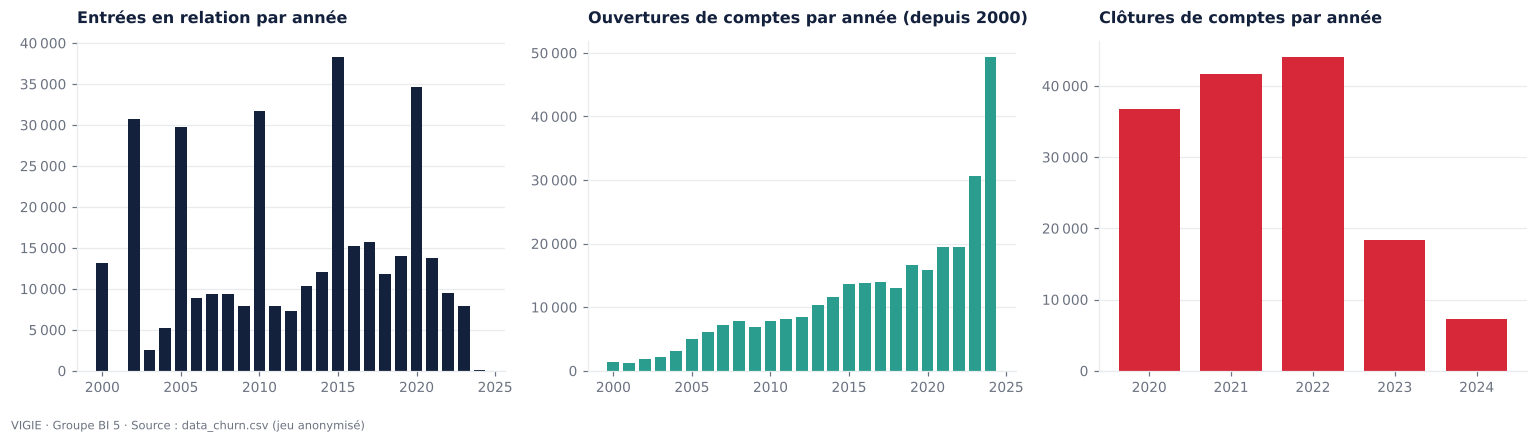

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, titre, base, couleur) in zip(axes, [
        ("CUST_OPENING_DATE", "Entrées en relation par année", clients, C["encre"]),
        ("ACCT_OPENING_DATE", "Ouvertures de comptes par année (depuis 2000)", comptes, C["retention"]),
        ("ACCT_CLOSE_DATE", "Clôtures de comptes par année", comptes, C["churn"])]):
    par_an = base[col].dropna().dt.year.value_counts().sort_index()
    par_an = par_an[par_an.index >= 2000]
    ax.bar(par_an.index, par_an.values, color=couleur, width=0.75)
    ax.yaxis.set_major_formatter(style.milliers)
    ax.set_title(titre, fontsize=10.5)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
style.enregistrer(fig, "01_univarie_dates")
plt.show()

**Lecture — dates**

* Toutes les dates sont **convertibles** (aucun format invalide) : la conversion `YYYYMMDD → date` est sûre.
* Elles ont des **précisions différentes**, à respecter : les dates de compte sont ramenées au **lundi**
  (grain hebdomadaire), les dates de revue et de produit au **1er du mois** (grain mensuel), et l'entrée en
  relation au début de trimestre, d'année ou de période de 5 ans.
* Les clôtures ne couvrent qu'**environ 47 mois** : c'est la fenêtre d'observation du churn, et la raison pour
  laquelle la série temporelle de la phase 4 est construite à la **semaine**.
* Les dates ayant été décalées, on raisonne en **durées** (ancienneté, délais), jamais en dates calendaires.

## 6. Outliers

Deux méthodes sont appliquées à chaque variable numérique :

* **IQR** : valeur hors de `[Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]` — robuste, ne suppose pas de loi normale ;
* **z-score** : `|x − moyenne| / écart-type > 3` — classique, mais sensible aux valeurs extrêmes elles-mêmes.

La méthode **IQR est notre référence**, car aucune de ces variables ne suit une loi normale.

In [23]:
def outliers(serie: pd.Series) -> dict:
    s = serie.dropna().astype(float)
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    bas, haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return {
        "n": len(s), "Borne basse IQR": bas, "Borne haute IQR": haut,
        "Outliers bas (IQR)": int((s < bas).sum()), "Outliers hauts (IQR)": int((s > haut).sum()),
        "Outliers IQR": int(((s < bas) | (s > haut)).sum()),
        "% IQR": round(((s < bas) | (s > haut)).mean() * 100, 1),
        "Outliers z-score": int((z.abs() > 3).sum()),
        "% z-score": round((z.abs() > 3).mean() * 100, 1),
    }


numeriques = {
    "ACCT_BALANCE": comptes["ACCT_BALANCE"], "AMOUNT": comptes["AMOUNT"], "FIXEDRATE": comptes["FIXEDRATE"],
    "SALARY": clients["SALARY"], "BIRTH_PERIOD": clients["BIRTH_PERIOD"],
    "NB_COMPTES (dérivée)": clients.loc[clients["NB_COMPTES"] > 0, "NB_COMPTES"],
    "ANCIENNETE_CLIENT (dérivée)": clients["ANCIENNETE_CLIENT"],
    "MOIS_DEPUIS_REVUE (dérivée)": clients["MOIS_DEPUIS_REVUE"],
}
tab_outliers = pd.DataFrame({nom: outliers(s) for nom, s in numeriques.items()}).T
display(tab_outliers.round(1))

,n,Borne basse IQR,Borne haute IQR,Outliers bas (IQR),Outliers hauts (IQR),Outliers IQR,% IQR,Outliers z-score,% z-score
ACCT_BALANCE,309831.0,-2400.0,4000.0,39899.0,59463.0,99362.0,32.1,1685.0,0.5
AMOUNT,255796.0,-28488.5,47493.1,1123.0,50113.0,51236.0,20.0,852.0,0.3
FIXEDRATE,40442.0,4.8,14.8,4299.0,0.0,4299.0,10.6,258.0,0.6
SALARY,112277.0,-500.0,1900.0,0.0,17899.0,17899.0,15.9,1620.0,1.4
BIRTH_PERIOD,339679.0,1922.5,2022.5,0.0,0.0,0.0,0.0,0.0,0.0
NB_COMPTES (dérivée),319040.0,1.0,1.0,0.0,45465.0,45465.0,14.3,5325.0,1.7
ANCIENNETE_CLIENT (dérivée),347422.0,-11.9,36.1,0.0,0.0,0.0,0.0,0.0,0.0
MOIS_DEPUIS_REVUE (dérivée),336120.0,-52.9,143.2,0.0,10468.0,10468.0,3.1,6693.0,2.0


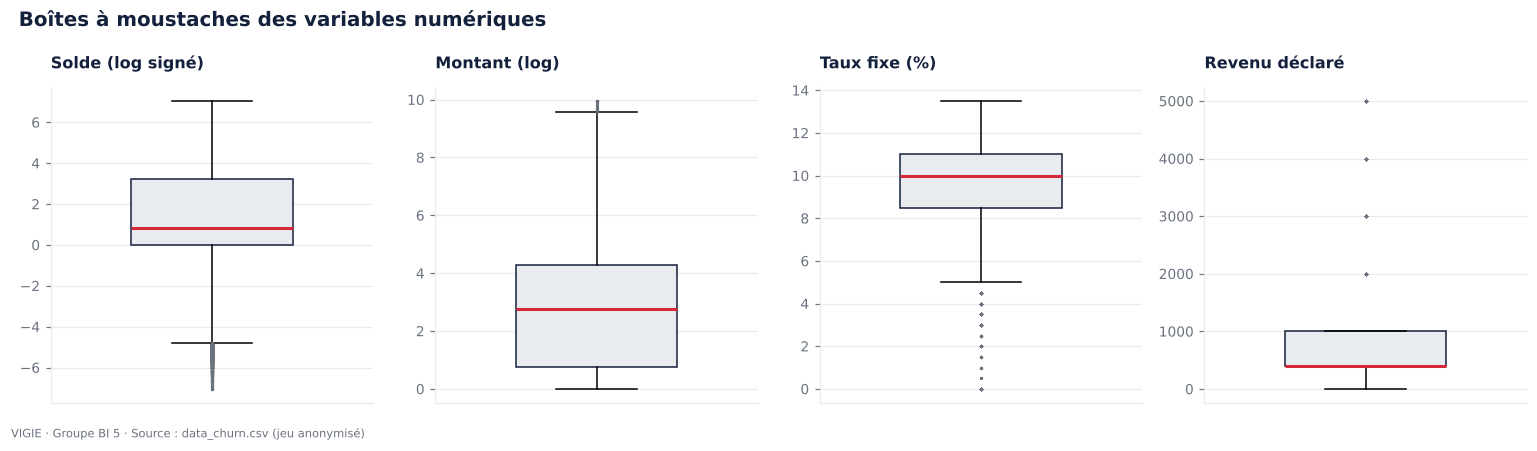

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, (nom, s, transfo) in zip(axes, [
        ("Solde (log signé)", comptes["ACCT_BALANCE"], log_signe),
        ("Montant (log)", comptes["AMOUNT"], lambda x: np.log10(1 + x.clip(lower=0))),
        ("Taux fixe (%)", comptes["FIXEDRATE"], lambda x: x),
        ("Revenu déclaré", clients["SALARY"], lambda x: x)]):
    ax.boxplot(transfo(s.dropna()), vert=True, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=C["brume"], color=C["encre"]),
               medianprops=dict(color=C["churn"], lw=2),
               flierprops=dict(marker=".", markersize=2, alpha=0.25, markerfacecolor=C["gris"], markeredgecolor=C["gris"]))
    ax.set_title(nom, fontsize=10.5)
    ax.set_xticks([])
fig.suptitle("Boîtes à moustaches des variables numériques", x=0.01, ha="left", fontweight="bold",
             color=C["encre"], fontsize=13)
fig.tight_layout()
style.enregistrer(fig, "01_outliers_boxplots")
plt.show()

In [25]:
# Qui sont les « outliers » du solde ? Décomposition par signe et par famille de comptes.
s = comptes[comptes["ACCT_BALANCE"].notna()].copy()
q1, q3 = s["ACCT_BALANCE"].quantile([.25, .75])
bas, haut = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
s["OUTLIER"] = (s["ACCT_BALANCE"] < bas) | (s["ACCT_BALANCE"] > haut)
s["SIGNE"] = np.where(s["ACCT_BALANCE"] < 0, "Solde négatif (débiteur)", np.where(s["ACCT_BALANCE"] == 0, "Solde nul", "Solde positif"))
display(s.groupby("SIGNE")["OUTLIER"].agg(Comptes="size", Outliers_IQR="sum", Part_outliers="mean").round(3))
par_famille = s.groupby("ACCOUNT_TYPE_DESC")["OUTLIER"].agg(Comptes="size", Part_outliers="mean")
par_famille["Solde médian"] = s.groupby("ACCOUNT_TYPE_DESC")["ACCT_BALANCE"].median()
display(par_famille.sort_values("Part_outliers", ascending=False).round(3))

,Comptes,Outliers_IQR,Part_outliers
SIGNE,,,
Solde nul,62994,0,0.000
Solde négatif (débiteur),60387,39899,0.661
Solde positif,186450,59463,0.319


,Comptes,Part_outliers,Solde médian
ACCOUNT_TYPE_DESC,,,
Credit immobilier,15953,0.944,-27000.0
Credit investissement,3403,0.916,-34000.0
Credit automobile,1187,0.881,-15000.0
Credit consommation,15495,0.558,-3200.0
Comptes courants,22224,0.440,290.0
Contentieux,14289,0.396,-1100.0
Placements a terme,5790,0.331,0.0
Epargne,176588,0.255,200.0
Financement court terme,22270,0.211,0.0


**Lecture — outliers**

* **Solde** : 32 % des soldes sortent des bornes IQR, comme annoncé par les tuteurs. Ce n'est **pas** un tiers
  d'erreurs. La décomposition le montre : les familles de **crédit** (immobilier, investissement, automobile) ont
  un solde médian négatif et sont à ≈ 90 % « hors bornes » ; le crédit à la consommation l'est à 56 %. La raison est
  mécanique : la majorité des comptes sont de l'épargne à petit solde, ce qui resserre l'intervalle IQR à
  [−2 400 ; 4 000]. Un solde négatif est donc une **information métier** (compte débiteur), pas une anomalie.
* **Montant** : 20 % d'outliers, presque tous vers le haut (gros encours), dont l'accumulation sur la valeur plafond.
* **Taux fixe** : 10,6 % d'outliers, tous vers le bas (taux inférieurs à 4,8 %). L'essentiel des taux est
  concentré entre 8,5 % et 11 % ; les taux faibles forment un second groupe de valeurs, minoritaire, que l'on conserve.
* **Revenu déclaré** : 15,9 % d'outliers, tous vers le haut. La moitié des revenus déclarés vaut 400, donc toute
  valeur ≥ 2 000 sort des bornes. C'est un effet de l'arrondi, pas une anomalie.
* Le **z-score** détecte bien moins de points que l'IQR sur les montants : les valeurs extrêmes gonflent
  l'écart-type et se masquent elles-mêmes. C'est pourquoi l'IQR est notre méthode de référence.

**Décision.** Aucune ligne n'est supprimée pour cause d'outlier. Dans l'entrepôt, on conserve la valeur et on ajoute
un indicateur de sens (`est_debiteur`) ; dans les analyses, on utilise la **médiane** et des **tranches** plutôt que
la moyenne. Ces variables de solde et de montant sont de toute façon écartées du modèle de churn (fuite de cible).

## 7. Tableau de synthèse par variable

Livrable du jalon 1 : pour chaque variable — type, % de manquants, nombre d'outliers, méthode, décision proposée.

In [26]:
types = {
    "CUSTOMER_NO": "Identifiant", "ACCOUNT_NO": "Identifiant", "BRANCH_GROUP": "Qualitative (21)",
    "NATIONALITY_REGION": "Qualitative (6)", "RESIDENCE_REGION": "Qualitative (6)", "MARITAL_STATUS": "Qualitative (4)",
    "BIRTH_PERIOD": "Quantitative discrète", "CUST_OPENING_DATE": "Date (précision variable)",
    "NATURE_CLIENT": "Qualitative (5)", "PARTYCLASS": "Qualitative (4)", "LOB": "Qualitative (6)",
    "SCORE_KYC": "Qualitative ordinale (5)", "COMPLETED_FILE": "Binaire (YES / vide)",
    "LAST_REVIEW_DATE": "Date (mois)", "NEXT__REVIEW_DATE": "Date (mois)", "INDUSTRY": "Qualitative (21)",
    "SALARY": "Quantitative arrondie", "ACCOUNT_STATUS": "Binaire — cible", "ACCT_OPENING_DATE": "Date (semaine)",
    "ACCT_CLOSE_DATE": "Date (semaine)", "ACCOUNT_CATEGORY": "Qualitative (14)", "ACCOUNT_TYPE_DESC": "Qualitative (14)",
    "CURRENCY": "Qualitative (5)", "CLOSURE_REASON": "Qualitative (12)", "ACCT_BALANCE": "Quantitative continue",
    "PRODUCT_GROUP": "Qualitative (12)", "PRODUCT_LINE": "Qualitative (4)", "STARTDATE": "Date (mois)",
    "MATURITYDATE": "Date (mois)", "AMOUNT": "Quantitative continue", "FIXEDRATE": "Quantitative discrète",
    "PRODUCT_STATUS": "Qualitative (7)",
}
nature_vide = {
    "ACCOUNT_NO": "Structurel (client sans compte)", "ACCOUNT_STATUS": "Structurel (client sans compte)",
    "ACCT_CLOSE_DATE": "Métier (compte actif)", "CLOSURE_REASON": "Métier (compte actif)",
    "ACCT_OPENING_DATE": "Lié à la clôture ⚠", "ACCOUNT_CATEGORY": "Lié à la clôture ⚠",
    "ACCOUNT_TYPE_DESC": "Lié à la clôture ⚠", "CURRENCY": "Lié à la clôture ⚠", "ACCT_BALANCE": "Lié à la clôture ⚠",
    "PRODUCT_GROUP": "Lié à la clôture ⚠", "PRODUCT_LINE": "Lié à la clôture ⚠", "AMOUNT": "Lié à la clôture ⚠",
    "STARTDATE": "Métier (produit sans échéance)", "MATURITYDATE": "Métier (produit sans échéance)",
    "FIXEDRATE": "Métier (produit sans taux)", "PRODUCT_STATUS": "Métier (produit sans échéance)",
    "SALARY": "Déclaratif", "MARITAL_STATUS": "Déclaratif / anonymisation", "BIRTH_PERIOD": "Déclaratif / anonymisation",
    "COMPLETED_FILE": "Signifiant (dossier incomplet)", "CUST_OPENING_DATE": "Anonymisation",
    "LAST_REVIEW_DATE": "Structurel (client sans compte)", "NEXT__REVIEW_DATE": "Structurel (client sans compte)",
    "SCORE_KYC": "Résiduel",
}
decision = {
    "CUSTOMER_NO": "Clé de la dimension client ; jamais affiché",
    "ACCOUNT_NO": "Clé du fait compte ; lignes sans compte → dimension client seulement",
    "BRANCH_GROUP": "Dimension agence ; AG00 = « masqué »",
    "NATIONALITY_REGION": "Conserver ; redondante avec la résidence",
    "RESIDENCE_REGION": "Conserver ; regrouper les modalités rares",
    "MARITAL_STATUS": "Vide → modalité « Non renseigné »",
    "BIRTH_PERIOD": "Dériver l'âge et la tranche d'âge",
    "CUST_OPENING_DATE": "Convertir ; dériver l'ancienneté client",
    "NATURE_CLIENT": "Conserver ; TRPP/TRPM → « Autre »",
    "PARTYCLASS": "Conserver (segment commercial)",
    "LOB": "Joindre TARGET.xlsx ; redondante avec PARTYCLASS",
    "SCORE_KYC": "Conserver ; vide → « Non renseigné »",
    "COMPLETED_FILE": "Recoder en 0/1 (vide = incomplet)",
    "LAST_REVIEW_DATE": "Convertir ; dériver les mois depuis la revue",
    "NEXT__REVIEW_DATE": "Convertir ; dériver les mois avant la revue",
    "INDUSTRY": "Joindre INDUSTRY.xlsx ; Z = non renseigné",
    "SALARY": "Conserver le vide (non déclaré) ; traiter en tranches",
    "ACCOUNT_STATUS": "Cible : Closed = 1, Active = 0",
    "ACCT_OPENING_DATE": "Convertir ; exclue du modèle (fuite)",
    "ACCT_CLOSE_DATE": "Garder la 1re date ; série temporelle ; exclue du modèle (fuite)",
    "ACCOUNT_CATEGORY": "Joindre le référentiel ; exclue du modèle (fuite)",
    "ACCOUNT_TYPE_DESC": "Redondante avec ACCOUNT_CATEGORY",
    "CURRENCY": "Joindre le référentiel ; exclue du modèle (fuite)",
    "CLOSURE_REASON": "Joindre le référentiel ; exclue du modèle (fuite)",
    "ACCT_BALANCE": "Conserver les négatifs (débiteurs) ; médiane et tranches ; exclue du modèle (fuite)",
    "PRODUCT_GROUP": "Dimension produit ; exclue du modèle (fuite)",
    "PRODUCT_LINE": "Dimension produit ; exclue du modèle (fuite)",
    "STARTDATE": "Convertir ; usage descriptif",
    "MATURITYDATE": "Convertir ; usage descriptif",
    "AMOUNT": "Conserver ; pic au plafond = artefact ; exclue du modèle (fuite)",
    "FIXEDRATE": "Conserver ; usage descriptif",
    "PRODUCT_STATUS": "Usage descriptif ; exclue du modèle (fuite)",
}
synthese = pd.DataFrame({
    "Type": pd.Series(types),
    "% manquants (lignes)": manquants["% manquants (lignes)"],
    "% manquants (grain naturel)": manquants["% manquants (grain naturel)"],
    "Nature du vide": pd.Series(nature_vide),
})
synthese["Outliers IQR"] = tab_outliers["Outliers IQR"].reindex(synthese.index)
synthese["Outliers z-score"] = tab_outliers["Outliers z-score"].reindex(synthese.index)
synthese["Décision proposée"] = pd.Series(decision)
synthese = synthese.loc[list(brut.columns)]
synthese["Nature du vide"] = synthese["Nature du vide"].fillna("—")
affichage = synthese.copy()
for c in ["Outliers IQR", "Outliers z-score"]:
    affichage[c] = affichage[c].map(lambda v: "—" if pd.isna(v) else fr(v))
display(affichage)

,Type,% manquants (lignes),% manquants (grain naturel),Nature du vide,Outliers IQR,Outliers z-score,Décision proposée
CUSTOMER_NO,Identifiant,0.0,0.0,—,—,—,Clé de la dimension client ; jamais affiché
ACCOUNT_NO,Identifiant,9.1,0.0,Structurel (client sans compte),—,—,Clé du fait compte ; lignes sans compte → dime...
NATIONALITY_REGION,Qualitative (6),0.0,0.0,—,—,—,Conserver ; redondante avec la résidence
RESIDENCE_REGION,Qualitative (6),0.0,0.0,—,—,—,Conserver ; regrouper les modalités rares
MARITAL_STATUS,Qualitative (4),16.5,10.9,Déclaratif / anonymisation,—,—,Vide → modalité « Non renseigné »
CUST_OPENING_DATE,Date (précision variable),3.5,4.3,Anonymisation,—,—,Convertir ; dériver l'ancienneté client
BIRTH_PERIOD,Quantitative discrète,13.2,6.4,Déclaratif / anonymisation,0,0,Dériver l'âge et la tranche d'âge
NATURE_CLIENT,Qualitative (5),0.0,0.0,—,—,—,Conserver ; TRPP/TRPM → « Autre »
BRANCH_GROUP,Qualitative (21),0.0,0.0,—,—,—,Dimension agence ; AG00 = « masqué »
SCORE_KYC,Qualitative ordinale (5),0.2,0.2,Résiduel,—,—,Conserver ; vide → « Non renseigné »


In [27]:
# Export du tableau de synthèse (livrable du jalon 1) — agrégats uniquement.
lignes_md = [
    "# Synthèse par variable — jalon 1",
    "",
    f"> Généré par `01_etl/notebooks/01_analyse_univariee.ipynb` · {config.NOM_PROJET} · {config.GROUPE}  ",
    f"> Fichier analysé : `data_churn.csv` — SHA-256 `{empreinte['sha256'][:16]}…` — {fr(len(brut))} lignes, {brut.shape[1]} colonnes.",
    "",
    "Méthode outliers : **IQR** (hors de `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]`, méthode de référence) et **z-score** (`|z| > 3`), "
    "calculés au grain naturel de la variable (compte ou client). Aucune ligne n'est supprimée pour cause d'outlier.",
    "",
    "| Variable | Type | % manquants (lignes) | % manquants (grain naturel) | Nature du vide | Outliers IQR | Outliers z-score | Décision proposée |",
    "|---|---|---:|---:|---|---:|---:|---|",
]
for var, r in affichage.iterrows():
    lignes_md.append(
        f"| `{var}` | {r['Type']} | {r['% manquants (lignes)']:.1f} | {r['% manquants (grain naturel)']:.1f} | "
        f"{r['Nature du vide']} | {r['Outliers IQR']} | {r['Outliers z-score']} | {r['Décision proposée']} |")
lignes_md += [
    "",
    "**Variables dérivées contrôlées** (grain client) :",
    "",
    "| Variable dérivée | Outliers IQR | % | Outliers z-score | Commentaire |",
    "|---|---:|---:|---:|---|",
]
commentaires = {
    "NB_COMPTES (dérivée)": "Distribution très concentrée sur 1 : tout client multi-comptes sort des bornes. Information utile, conservée.",
    "ANCIENNETE_CLIENT (dérivée)": "Aucune valeur aberrante.",
    "MOIS_DEPUIS_REVUE (dérivée)": "Revues très anciennes : dossiers non revus, information utile.",
}
for nom, com in commentaires.items():
    r = tab_outliers.loc[nom]
    lignes_md.append(f"| {nom} | {fr(r['Outliers IQR'])} | {r['% IQR']:.1f} | {fr(r['Outliers z-score'])} | {com} |")
(RACINE / "01_etl" / "synthese_variables.md").write_text("\n".join(lignes_md) + "\n", encoding="utf-8")
print("Tableau exporté : 01_etl/synthese_variables.md")

Tableau exporté : 01_etl/synthese_variables.md


## Conclusion de la phase 1

1. **Intégrité vérifiée** : volumes conformes au document des tuteurs, aucune date invalide, aucune clé orpheline.
2. **Grain clarifié** : le fichier mélange trois grains. Nous retenons le **compte** pour l'entrepôt et les KPI,
   et le **client** pour la segmentation et la prédiction.
3. **Churn défini** : compte clos. Taux de ≈ 40 % par ligne, ≈ 36 % par compte, ≈ 32 % par client — et **aucun
   client mixte**, ce qui rend la définition au grain client sans ambiguïté.
4. **Valeurs manquantes typées** : structurelles, métier, déclaratives… et surtout **liées à la clôture**, qui
   constituent une fuite de cible à neutraliser.
5. **Outliers interprétés, pas supprimés** : les soldes négatifs sont des comptes débiteurs, les pics extrêmes
   viennent du plafonnement.

➡ Suite : analyse bivariée (bonus) dans `02_analyse_bivariee.ipynb`, puis conception de l'entrepôt (phase 2).